In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.19.1
NumPy version: 2.1.3


In [2]:
# Load the dataset 
import tensorflow as tf
from tensorflow import keras
(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


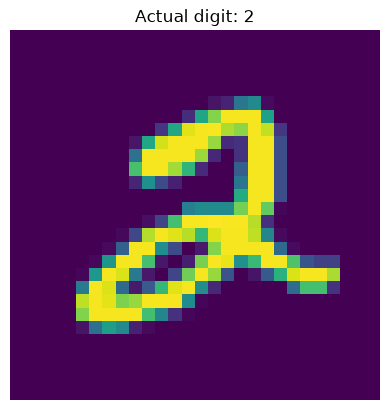

In [3]:
# Display the smaple image
index=5
plt.imshow(X_train[index])
plt.title(f"Actual digit: { y_train[index]}")
plt.axis('off')
plt.show()

In [4]:
# Normalize the pixel 
# Convert the pixel values from 0 -255 to 0-1
X_train=X_train.astype("float32")/255.0
X_test=X_test.astype("float32")/255.0 
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)
Minimum pixel: 0.0
Maximum pixel: 1.0


In [5]:
# Add the grayscale channel dimension
X_train=X_train[...,np.newaxis]
X_test=X_test[...,np.newaxis]
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)
Minimum pixel: 0.0
Maximum pixel: 1.0


## Build the CNN Architecture

In [6]:
model=tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),

    # First Convolution block
    tf.keras.layers.Conv2D(
        filters =32,
        kernel_size=(3,3),
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    # Second convolution block
    tf.keras.layers.Conv2D(
        filters=64,
        kernel_size=(3,3),
        padding='same',
        activation='relu'
    ),
    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         802,880 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 822,346 (3.14 MB)

 Trainable params: 822,346 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

## Compile the model

In [7]:
model.compile(optimizer='adam',
             loss='sparse_categorical_crossentropy',
             metrics=['accuracy'])

## Train the CNN

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping]
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.9537 - loss: 0.1520 - val_accuracy: 0.9880 - val_loss: 0.0495
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9854 - loss: 0.0466 - val_accuracy: 0.9887 - val_loss: 0.0398
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9908 - loss: 0.0290 - val_accuracy: 0.9887 - val_loss: 0.0419
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9932 - loss: 0.0212 - val_accuracy: 0.9905 - val_loss: 0.0381
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9958 - loss: 0.0140 - val_accuracy: 0.9907 - val_loss: 0.0357


## Evaluate the model 

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9909 - loss: 0.0296
Test Loss: 0.0296
Test Accuracy: 99.09%


## Plot training and validation accuracy

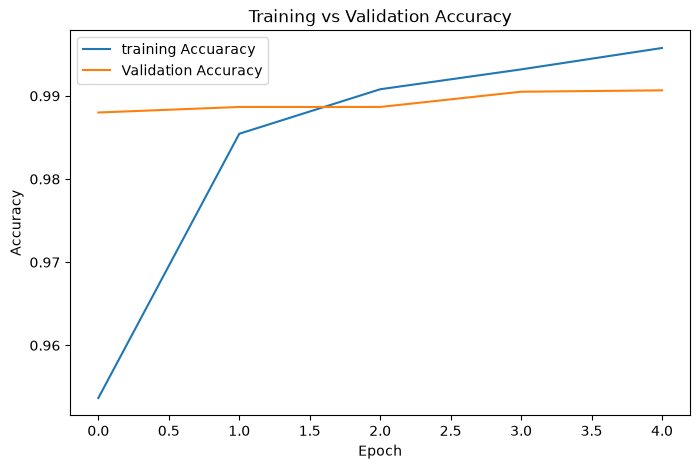

In [10]:
plt.figure(figsize=(8,5))
plt.plot(
    history.history['accuracy'],
    label="training Accuaracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

##  Plot training and Validation Loss

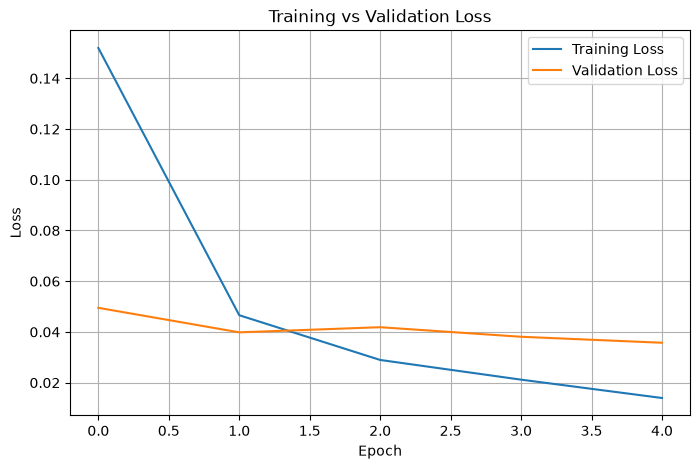

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Predict all test images 

In [12]:
import numpy as np 
predictions=model.predict(
    X_test,batch_size=64,verbose=1
)
predicted_digits=np.argmax(predictions,axis=1)
print("Predictions:", predicted_digits.shape)
print("First 10 predicted:", predicted_digits[:10])
print("First 10 actual:", y_test[:10])

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step   
Predictions: (10000,)
First 10 predicted: [7 2 1 0 4 1 4 9 5 9]
First 10 actual: [7 2 1 0 4 1 4 9 5 9]


157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step 


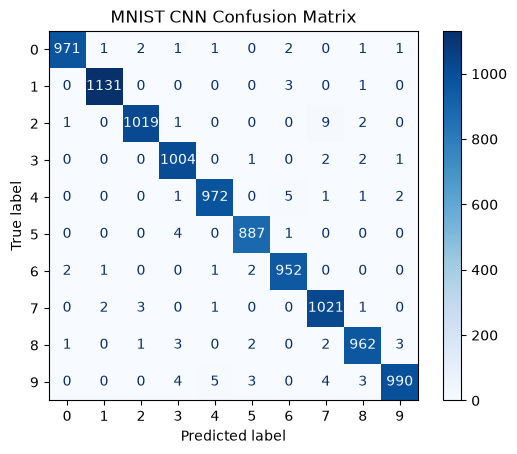

In [13]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
# Predict all test images 
predictions = model.predict(
    X_test,
    batch_size=64,
    verbose=1
)

predicted_digits = np.argmax(predictions, axis=1)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    predicted_digits,
    labels=np.arange(10)
)

# Display confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

display.plot(cmap="Blues", values_format="d")
plt.title("MNIST CNN Confusion Matrix")
plt.show()

## Find the incorrect Predictions

In [16]:
wrong_indices =np.where(predicted_digits!= y_test)[0]
print("Incorrect Predictions:",len(wrong_indices))
print("Correct Predictions:",len(y_test)-len(wrong_indices))
print("Total test images:",len(y_test))

Incorrect Predictions: 91
Correct Predictions: 9909
Total test images: 10000


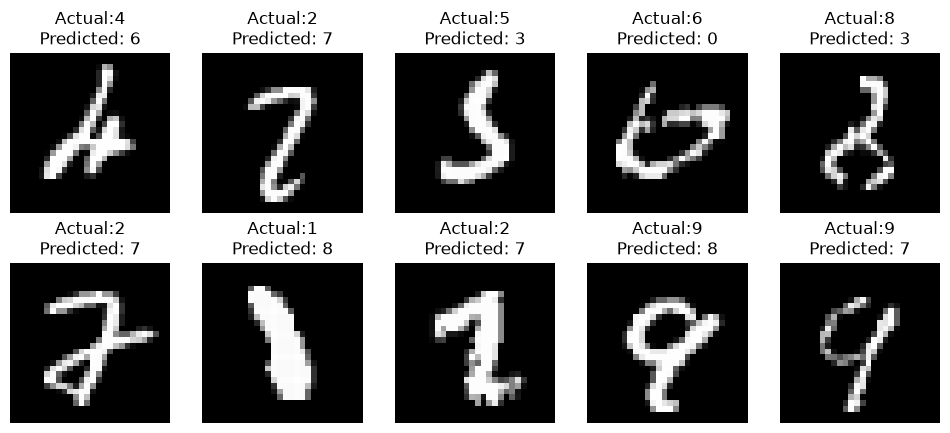

In [18]:
# Visualize the first 10 mistakes
plt.figure(figsize=(12,5))
for i, index in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[index].squeeze(),cmap='gray')
    plt.title(f"Actual:{y_test[index]}\n"
             f"Predicted: {predicted_digits[index]}")
    plt.axis("off")
plt.show()


## Save the trained model 

In [19]:
model.save('mnist_cnn.keras')
print("Model saved successfully!!!")

Model saved successfully!!!
